# 실험 3: 3x3 양자 런 — SAFE vs exact-only (parameter-shift)

케이스 하나(3x3 인스턴스 0, seed 120490, 상수 초기화 c = 0.1)에서 두 arm을 QPU로 학습한다.

| arm | 시작점 | QPU 학습 |
|---|---|---|
| SAFE | PADO LWPP mw3 100 step → 증류(\|θ\| ≤ 0.3 제거) 후의 θ, 증류된 회로 (각도 61개) | parameter-shift 5 step |
| exact-only | 상수 초기값 θ_init, 전체 회로 (각도 114개) | parameter-shift 20 step |

노트북 흐름: 설정 → (API 키) → backend → 1. 문제와 시작점 → 2. 회로 → 3. 큐비트 배치와 transpile → 4. parameter-shift 학습 → 5. 요약

- 시작점은 `prepare_start_points.py`가 GPU에서 미리 만든 `results_on_MI300X/exp3_quantum_3x3/grid3x3_inst0_seed120490/start_points/`를 읽는다.
- 결과는 `results_on_<backend 이름>/exp3_quantum_3x3/grid3x3_inst0_seed120490/<arm>/`에 step마다 저장된다. 중간에 끊기면 학습 셀(4-3)을 다시 실행하면 이어서 돌고, 끝난 arm은 건너뛴다.

**실기기로 바꾸는 법**: 설정 셀에서 `BACKEND_MODE = "ibm"`, `IBM_BACKEND`에 기기 이름을 넣고, API 키 셀에 키를 넣어 실행한 뒤 키를 지운다. 나머지 셀은 그대로다.

## 설정

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rustworkx as rx
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2, QiskitRuntimeService
from qiskit_ibm_runtime.fake_provider import FakeNighthawk

from common import save_json, save_qasm   # exp3_quantum_3x3/common.py: JSON 저장, QASM 저장

# ---- 실행 설정 (보통 여기만 바꾼다)
BACKEND_MODE = "fake"         # "fake": 이 컴퓨터에서 FAKE_BACKEND의 노이즈 모델로 시뮬레이션 / "ibm": 실제 IBM 양자컴퓨터
FAKE_BACKEND = FakeNighthawk  # Nighthawk(정사각 격자 연결) 스냅샷. heavy-hex 기기로 보려면 FakeFez를 같은 모듈에서 import
IBM_BACKEND = ""              # 실기기 이름. BACKEND_MODE == "ibm"일 때만 쓴다
SHOTS = 1024                  # 회로 하나를 몇 번 측정해서 기댓값을 낼지
RESILIENCE_LEVEL = 1          # 실기기 오류 완화: 0 없음, 1 측정(readout) 오류 보정. fake 모드에서는 적용되지 않는다
STEPS = {"safe": 5, "exact_only": 20}   # arm별 parameter-shift 업데이트 횟수
LR = 0.02                     # Adam 학습률 (고전 실험과 같음)
SEED_TRANSPILER = 0           # transpile 결과가 실행마다 같도록 고정
TWO_Q_GATE = "cz"             # 배치 점수에 쓸 기기의 2큐비트 게이트 (Nighthawk, Heron 계열은 cz)

# ---- 경로
REPO = Path.cwd().parent      # 이 노트북은 exp3_quantum_3x3/ 폴더에서 실행한다고 가정
CASE = "grid3x3_inst0_seed120490"
START_DIR = REPO / "results_on_MI300X" / "exp3_quantum_3x3" / CASE / "start_points"   # 두 arm의 시작점

## API 키 (실기기에서만)

`BACKEND_MODE = "ibm"`일 때만 쓰인다. 키를 넣고 아래 셀까지 실행한 뒤, 이 셀의 키는 지운다. 키는 파일에 저장하지 않는다.

In [2]:
TOKEN = ""     # IBM Cloud API 키 -- 입력해서 아래 backend 셀까지 실행한 뒤 지운다
INSTANCE = ""  # IBM Cloud CRN 또는 인스턴스 이름 (없으면 비워 둔다)

## backend

`FakeNighthawk`는 qiskit-ibm-runtime에 들어 있는 Nighthawk(정사각 격자 연결) 스냅샷이다. 패키지 스스로 "이 fake backend의 오류 값은 실제 Nighthawk의 일반적인 오류 값을 나타내도록 만든 것이 아니다"라고 경고하므로, fake 결과의 노이즈 크기는 실기기 예측으로 쓰지 않는다. 연결 구조와 transpile 결과, 코드 경로 검증용이다.

In [3]:
import warnings
# fake_nighthawk는 "오류 값이 실제 기기를 대표하지 않는다"는 경고를 낸다 (위 설명 참고). 출력이 길어져 끈다.
warnings.filterwarnings("ignore", message="Properties of fake_nighthawk")

if BACKEND_MODE == "ibm":
    # 실기기: 키로 IBM Quantum Platform에 접속해 기기를 고른다 (키는 파일에 저장하지 않음)
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=TOKEN, instance=INSTANCE or None)
    backend = service.backend(IBM_BACKEND)
else:
    # fake: 기기 스냅샷(연결 구조 + 노이즈 모델)을 이 컴퓨터에서 시뮬레이션
    backend = FAKE_BACKEND()

# 결과 폴더 이름에 기기 이름이 들어간다 (results_on_<기기 이름>/...)
OUT_ROOT = REPO / f"results_on_{backend.name}" / "exp3_quantum_3x3" / CASE
print(backend.name, backend.num_qubits, "qubits ->", OUT_ROOT.relative_to(REPO))

fake_nighthawk 120 qubits -> results_on_fake_nighthawk/exp3_quantum_3x3/grid3x3_inst0_seed120490


## 1. 문제와 시작점

In [4]:
# 시작점 파일 두 개: circuit.json(게이트 목록), params.json(θ 값, brute force E_min/E_max, 무노이즈 에너지)
circ_json = json.loads((START_DIR / "circuit.json").read_text())
start = json.loads((START_DIR / "params.json").read_text())
n, e_min, e_max = circ_json["n_qubits"], start["e_min"], start["e_max"]
ar = lambda e: (e_max - e) / (e_max - e_min)   # approximation ratio: E_max이면 0, 바닥 상태 E_min이면 1

# arm별 회로와 시작 θ
#   exact-only: 전체 회로(각도 114개)와 상수 초기값
#   SAFE      : 증류 후 남은 게이트만 있는 회로(각도 61개)와 사전학습·증류를 거친 θ
gates = {"exact_only": circ_json["gates"], "safe": circ_json["pruned_gates"]}
theta0 = {"exact_only": np.array(start["theta_init"]), "safe": np.array(start["theta_safe_start"])}
e_start = {"exact_only": start["exact_energy"]["exact_only_start"], "safe": start["exact_energy"]["safe_start"]}
for arm in ["safe", "exact_only"]:
    print(f"{arm:10s} angles={len(theta0[arm]):3d}  circuits/step={2 * len(theta0[arm]) + 1:3d}  "
          f"noiseless start AR={ar(e_start[arm]):.4f}")
print(f"brute force: E_min={e_min:.6f}, E_max={e_max:.6f}")

safe       angles= 61  circuits/step=123  noiseless start AR=0.9311
exact_only angles=114  circuits/step=229  noiseless start AR=0.5291
brute force: E_min=-8.656307, E_max=9.354969


## 2. 회로와 관측량

게이트 순서는 `circuit.json`과 같다. 각도 규약 R_P(θ) = exp(−iθP/2)는 Qiskit의 `rzz`, `rz`, `rx`와 같다. 파라미터는 `ParameterVector`로 만들어 행렬의 열 순서가 θ 번호와 같게 한다(이름이 `t10`, `t2`처럼 정렬되는 것을 피함). 마지막 줄은 노이즈 없는 Qiskit 에너지가 PennyLane으로 계산해 둔 시작점 에너지와 같은지 확인한다.

In [5]:
# 관측량 H = Σ J_ij Z_i Z_j + Σ h_i Z_i  (문제 해밀토니안)
H = SparsePauliOp.from_sparse_list([("ZZ", [u, v], w) for u, v, w in circ_json["edges"]] +
                                   [("Z", [q], h) for q, h in circ_json["fields"]], num_qubits=n)

# arm별 파라미터 회로: circuit.json의 게이트를 순서대로 Qiskit 게이트로 옮긴다
circuits = {}
for arm in ["safe", "exact_only"]:
    theta = ParameterVector("theta", len(theta0[arm]))   # theta[0], theta[1], ... 번호 순서가 θ 배열 순서와 같다
    qc = QuantumCircuit(n)
    for g in gates[arm]:
        if g["gate"] == "H":
            qc.h(g["wires"][0])
        elif g["gate"] == "RZZ":                         # exp(-i θ ZZ / 2)
            qc.rzz(theta[g["param"]], *g["wires"])
        elif g["gate"] == "RZ":                          # exp(-i θ Z / 2)
            qc.rz(theta[g["param"]], g["wires"][0])
        elif g["gate"] == "RX":                          # exp(-i θ X / 2)
            qc.rx(theta[g["param"]], g["wires"][0])
    circuits[arm] = qc

    # 확인: 노이즈 없는 Qiskit 에너지 == 시작점 파일의 에너지(PennyLane으로 계산)
    e = float(StatevectorEstimator().run([(qc, H, theta0[arm])]).result()[0].data.evs)
    assert abs(e - e_start[arm]) < 1e-8, (arm, e, e_start[arm])
    print(f"{arm:10s} noiseless E(theta0) = {e:+.10f}  (start_points: {e_start[arm]:+.10f})")

safe       noiseless E(theta0) = -7.4149925623  (start_points: -7.4149925623)
exact_only noiseless E(theta0) = -0.1747624990  (start_points: -0.1747624990)


## 3. 큐비트 배치와 transpile

### 3-1. 큐비트 배치: 3x3 격자
transpile에 배치를 맡기면 논리 큐비트 9개가 기기의 아무 물리 큐비트에나 놓일 수 있다. 그러면 격자에서 이웃인 두 큐비트가 기기에서는 멀리 떨어져 SWAP이 늘어날 수 있다. 그래서 문제의 3x3 격자(최근접 이웃 연결 12개)가 기기의 연결 구조 안에 **그대로** 들어가는 물리 큐비트 배치를 직접 고른다.

1. 논리 격자 그래프: 큐비트 q = 3·i + j (i행 j열), 오른쪽·아래쪽 이웃과 연결 (12개).
2. 기기의 연결 그래프 안에서 이 격자가 부분 그래프로 들어가는 모든 배치를 찾는다 (`rustworkx.vf2_mapping`).
3. 배치마다 점수 = 격자 연결 12쌍의 2큐비트 게이트 오류 합 + 9큐비트의 측정 오류 합. 가장 작은 배치를 쓴다 (오류 값은 기기의 최신 보정 데이터 `backend.target`).
4. 두 arm 모두 같은 배치를 쓴다.

대각선(NNN) 연결 8개는 정사각 격자 기기에서도 바로 연결돼 있지 않으므로 transpile이 SWAP을 넣는다. heavy-hex 기기(예: FakeFez)에는 3x3 격자가 그대로 들어가는 배치가 없다. 그 경우에는 그렇게 출력하고 transpiler의 자동 배치를 쓴다.

In [6]:
# 1. 논리 3x3 격자의 최근접 이웃 연결
grid = rx.PyGraph()
grid.add_nodes_from(range(n))
for i in range(3):
    for j in range(3):
        if j + 1 < 3:
            grid.add_edge(3 * i + j, 3 * i + j + 1, None)       # 오른쪽 이웃
        if i + 1 < 3:
            grid.add_edge(3 * i + j, 3 * (i + 1) + j, None)     # 아래쪽 이웃

# 2. 기기 연결 그래프 안에 격자가 그대로 들어가는 모든 배치, 3. 오류 점수
coupling = backend.coupling_map.graph.to_undirected(multigraph=False)
twoq_err = backend.target[TWO_Q_GATE]
candidates = []
for mapping in rx.vf2_mapping(coupling, grid, subgraph=True, induced=False):   # {물리 큐비트: 논리 큐비트}
    layout = [0] * n
    for phys, logical in mapping.items():
        layout[logical] = phys                                  # layout[논리 큐비트] = 물리 큐비트
    score = 0.0
    for u, v in grid.edge_list():
        props = twoq_err.get((layout[u], layout[v])) or twoq_err.get((layout[v], layout[u]))
        score += props.error if props is not None and props.error is not None else 1.0
    for q in range(n):
        props = backend.target["measure"].get((layout[q],))
        score += props.error if props is not None and props.error is not None else 1.0
    candidates.append((score, layout))

if candidates:
    score, LAYOUT = min(candidates)
    print(f"3x3 격자 배치 {len(candidates)}개 중 오류 점수가 가장 작은 배치 (점수 {score:.4f})")
    print("물리 큐비트 번호를 논리 격자 모양으로 (행 i, 열 j):")
    for i in range(3):
        print("   " + "  ".join(f"{LAYOUT[3 * i + j]:4d}" for j in range(3)))
else:
    LAYOUT = None
    print(f"{backend.name}에는 3x3 격자가 그대로 들어가는 배치가 없다 (heavy-hex 등). transpiler 자동 배치를 쓴다.")

3x3 격자 배치 640개 중 오류 점수가 가장 작은 배치 (점수 0.0682)
물리 큐비트 번호를 논리 격자 모양으로 (행 i, 열 j):
     27    28    29
     37    38    39
     47    48    49


### 3-2. transpile

양자컴퓨터는 정해진 기본 게이트(Nighthawk는 CZ, RZ, SX, X)와 연결된 큐비트 쌍에서만 2큐비트 게이트를 실행할 수 있다. transpile은 위 회로를 그 조건에 맞는 회로(ISA 회로)로 바꾼다. `initial_layout=LAYOUT`으로 3-1에서 고른 배치를 고정하고, 연결되지 않은 쌍(대각선 NNN)만 SWAP으로 잇는다. 파라미터는 비워 둔 채로 한 번만 transpile하고, 학습 중에는 값만 바꿔 넣는다. 관측량 H도 회로가 놓인 물리 큐비트 번호에 맞게 옮긴다(`apply_layout`).

In [7]:
pm = generate_preset_pass_manager(optimization_level=3, backend=backend, initial_layout=LAYOUT,
                                  seed_transpiler=SEED_TRANSPILER)
isa, isa_H = {}, {}
for arm in ["safe", "exact_only"]:
    isa[arm] = pm.run(circuits[arm])                      # 기기용 회로 (파라미터는 비어 있음)
    isa_H[arm] = H.apply_layout(isa[arm].layout)          # 관측량도 같은 물리 큐비트로
    start_layout = isa[arm].layout.initial_index_layout(filter_ancillas=True)
    if LAYOUT is not None:
        assert start_layout == LAYOUT, (arm, start_layout, LAYOUT)   # 고른 격자 배치가 그대로 쓰였는지 확인
    two_q = [i for i in isa[arm].data if i.operation.num_qubits == 2]
    print(f"{arm:10s} 2-qubit gates={len(two_q)}  depth={isa[arm].depth()}  "
          f"2-qubit depth={isa[arm].depth(lambda i: i.operation.num_qubits == 2)}  "
          f"initial physical qubits={start_layout}")

safe       2-qubit gates=32  depth=73  2-qubit depth=15  initial physical qubits=[27, 28, 29, 37, 38, 39, 47, 48, 49]
exact_only 2-qubit gates=156  depth=309  2-qubit depth=83  initial physical qubits=[27, 28, 29, 37, 38, 39, 47, 48, 49]


## 4. parameter-shift 학습

### parameter-shift란
이 회로의 게이트는 모두 R_P(θ) = exp(−iθP/2) 꼴이다(P는 Z⊗Z, Z, X). 이런 게이트 하나의 각도 θ_i만 바꾸면 에너지 E는 θ_i에 대한 사인 곡선이 된다. 그래서 θ_i 방향의 기울기를 근사 없이 두 번의 측정으로 구할 수 있다.

  **g_i = ∂E/∂θ_i = ( E(θ + π/2·e_i) − E(θ − π/2·e_i) ) / 2**

여기서 e_i는 i번째 성분만 1인 벡터다(번호는 코드와 같이 0부터 센다). 즉 파라미터마다 "θ_i만 +π/2 옮긴 회로"와 "θ_i만 −π/2 옮긴 회로"를 한 번씩 돌려, 두 에너지의 차를 2로 나눈다. 평균을 내는 것이 아니라 차를 구한다.

### job 하나 = step 하나
한 step에 필요한 회로를 모두 한 job에 담아 보낸다. 실제로 보내는 것은 파라미터가 비어 있는 회로 1개, 관측량 H, 그리고 아래 파라미터 행렬이다. 이 셋을 묶은 것을 Qiskit에서는 PUB(primitive unified bloc, Estimator에 넣는 입력 단위)라고 한다.

```
estimator.run([ (ISA 회로, H, rows) ])        ← job 1개

rows (2N+1 행 × N 열), N = 파라미터 수 (SAFE 61, exact-only 114), 파라미터 번호 i = 0 .. N−1
  행 0      : θ                     → E(θ)       이 step의 에너지 (AR 기록용)
  행 1      : θ + π/2·e_0           → E_0+
  행 2      : θ − π/2·e_0           → E_0−
  행 3      : θ + π/2·e_1           → E_1+
  행 4      : θ − π/2·e_1           → E_1−
  ...
  행 2i+1   : θ + π/2·e_i           → E_i+
  행 2i+2   : θ − π/2·e_i           → E_i−
  ...
  행 2N     : θ − π/2·e_(N−1)       → E_(N−1)−

기울기  g_i = (E_i+ − E_i−) / 2        →  Adam으로 θ 업데이트  →  다음 step의 job
```

Estimator는 행마다 회로에 값을 넣어 별도의 회로로 실행하고, 회로마다 `SHOTS`번 측정한다. 그래서 바인딩된 회로 2N+1개를 리스트로 보내는 것과 실행 내용이 같다. 회로를 한 번만 transpile해 두고 값만 바꿔 보내므로 전송량이 작다는 점만 다르다. 마지막 업데이트 뒤에는 최종 θ의 에너지만 재는 회로 1개짜리 job을 하나 더 보낸다.

| arm | step 수 | job당 회로 | 총 job | 총 회로 |
|---|---|---|---|---|
| SAFE | 5 | 2·61 + 1 = 123 | 5 + 1 | 5·123 + 1 = 616 |
| exact-only | 20 | 2·114 + 1 = 229 | 20 + 1 | 20·229 + 1 = 4,581 |

매 step의 θ는 노이즈 없는 statevector로도 평가해(`energy_noiseless`) 하드웨어 노이즈와 최적화 진행을 나눠 볼 수 있게 한다.

### 4-1. Estimator 설정

In [8]:
estimator = EstimatorV2(mode=backend)          # mode=backend: job 모드 (step마다 job 하나)
estimator.options.default_shots = SHOTS        # 회로(행) 하나당 측정 횟수
if BACKEND_MODE == "ibm":
    estimator.options.resilience_level = RESILIENCE_LEVEL   # 실기기에서만 의미가 있다

### 4-2. job 하나의 구성 보기

SAFE arm의 첫 step에서 job 하나에 들어갈 파라미터 행렬을 만들어 앞부분만 출력해 본다. 아무것도 보내지 않는다. 4-3의 학습 루프도 같은 방식으로 행렬을 만든다.

In [9]:
theta = theta0["safe"]
k = len(theta)
rows = [theta.copy()]                      # 행 0: θ 그대로
for i in range(k):
    plus = theta.copy()
    plus[i] += np.pi / 2                   # 행 2i+1: θ_i만 +π/2
    minus = theta.copy()
    minus[i] -= np.pi / 2                  # 행 2i+2: θ_i만 −π/2
    rows += [plus, minus]
rows = np.array(rows)

print(f"rows 크기 = {rows.shape}  (2N+1 = {2 * k + 1}개 회로, N = {k}개 파라미터)")
for r in range(5):
    changed = np.flatnonzero(rows[r] != theta)
    if len(changed) == 0:
        print(f"  행 {r}: θ 그대로                → E(θ)")
    else:
        i = changed[0]
        sign = "+" if rows[r][i] > theta[i] else "−"
        print(f"  행 {r}: θ_{i}만 {sign}π/2 ({theta[i]:+.4f} → {rows[r][i]:+.4f}) → E_{i}{sign}")
print("  ...")
print(f"이 행렬, ISA 회로 1개, 관측량 H를 묶어 job 1개로 보낸다. 행마다 {SHOTS} shots씩 실행된다.")

rows 크기 = (123, 61)  (2N+1 = 123개 회로, N = 61개 파라미터)
  행 0: θ 그대로                → E(θ)
  행 1: θ_0만 +π/2 (+0.3263 → +1.8971) → E_0+
  행 2: θ_0만 −π/2 (+0.3263 → -1.2445) → E_0−
  행 3: θ_1만 +π/2 (-1.3019 → +0.2689) → E_1+
  행 4: θ_1만 −π/2 (-1.3019 → -2.8727) → E_1−
  ...
이 행렬, ISA 회로 1개, 관측량 H를 묶어 job 1개로 보낸다. 행마다 1024 shots씩 실행된다.


### 4-3. 학습 루프

arm마다 아래를 반복한다. 결과 파일 `params.json`은 step마다 덮어 써서 진행 상황을 남긴다. 이미 끝난 arm(최종 에너지까지 저장됨)은 건너뛴다.

1. 파라미터 행렬 `rows`를 만든다 (4-2와 같음).
2. job을 보내고 job ID를 먼저 저장한다. 실기기에서 기다리다 끊겨도 다음 실행 때 이 ID로 결과를 받아 온다.
3. 결과에서 E(θ)와 기울기 g_i = (E_i+ − E_i−)/2를 꺼낸다.
4. 같은 θ의 노이즈 없는 에너지를 statevector로 계산해 같이 기록한다.
5. Adam으로 θ를 업데이트하고 저장한다. Adam 식은 고전 실험의 `torch.optim.Adam`(β1 = 0.9, β2 = 0.999, ε = 1e-8)과 같다.

업데이트를 `STEPS[arm]`번 한 뒤 마지막으로 최종 θ의 에너지만 재는 job(회로 1개)을 보낸다.

In [10]:
for arm in ["safe", "exact_only"]:
    out = OUT_ROOT / arm
    (out / "qasm").mkdir(parents=True, exist_ok=True)
    path = out / "params.json"

    # ---- 이어서 돌리기: 끝난 arm은 건너뛰고, 중간에 멈춘 arm은 저장된 θ와 Adam 상태에서 다시 시작
    if path.exists():
        rec = json.loads(path.read_text())
        if rec["final"] is not None:
            print(f"{arm}: finished run found, skipped (results are never overwritten)")
            continue
    else:
        rec = {"arm": arm, "problem": CASE, "backend": backend.name, "e_min": e_min, "e_max": e_max,
               "config": {"shots": SHOTS, "resilience_level": RESILIENCE_LEVEL if BACKEND_MODE == "ibm" else None,
                          "steps": STEPS[arm], "lr": LR, "seed_transpiler": SEED_TRANSPILER,
                          "n_params": len(theta0[arm]), "circuits_per_step": 2 * len(theta0[arm]) + 1},
               "theta_start": theta0[arm].tolist(), "theta": theta0[arm].tolist(),
               "adam_m": [0.0] * len(theta0[arm]), "adam_v": [0.0] * len(theta0[arm]),
               "steps": [], "pending_job": None, "final": None}
    theta = np.array(rec["theta"])      # 현재 파라미터
    m = np.array(rec["adam_m"])         # Adam 1차 모멘트 (기울기의 이동 평균)
    v = np.array(rec["adam_v"])         # Adam 2차 모멘트 (기울기 제곱의 이동 평균)
    k = len(theta)

    # t = 0 .. STEPS-1: parameter-shift job + 업데이트,  t = STEPS: 최종 에너지 job
    for t in range(len(rec["steps"]), STEPS[arm] + 1):
        final = t == STEPS[arm]

        # ---- 1. 이번 job에 넣을 파라미터 행렬
        if final:
            rows = np.array([theta])                 # 최종 에너지: θ 하나 → 회로 1개
        else:
            rows = [theta.copy()]                    # 행 0: θ 그대로 → E(θ)
            for i in range(k):
                plus = theta.copy()
                plus[i] += np.pi / 2                 # 행 2i+1: θ_i만 +π/2 → E_i+
                minus = theta.copy()
                minus[i] -= np.pi / 2                # 행 2i+2: θ_i만 −π/2 → E_i−
                rows += [plus, minus]
            rows = np.array(rows)                    # (2k+1) × k

        # ---- 2. job 보내기 (회로 1개 + 관측량 + 행렬 = PUB 1개 = job 1개). job ID를 먼저 저장
        t0 = time.perf_counter()
        if rec["pending_job"] is not None and BACKEND_MODE == "ibm":
            job = service.job(rec["pending_job"])   # 지난번에 보내 놓고 못 받은 job
        else:
            job = estimator.run([(isa[arm], isa_H[arm], rows)])
            rec["pending_job"] = job.job_id()
            save_json(path, rec)

        # ---- 3. 결과: 행마다 기댓값 하나 (evs[r] = 행 r의 에너지, stds[r] = 그 표준오차)
        res = job.result()[0]
        evs = np.asarray(res.data.evs)
        stds = np.asarray(res.data.stds)
        energy = float(evs[0])                       # 행 0 = 이번 θ의 에너지

        # ---- 4. 같은 θ의 노이즈 없는 에너지 (비교용, 학습에는 쓰지 않음)
        e_noiseless = float(StatevectorEstimator().run([(circuits[arm], H, theta)]).result()[0].data.evs)

        row = {"t": t, "job_id": job.job_id(), "theta": theta.tolist(), "energy": energy,
               "energy_std": float(stds[0]), "ar": ar(energy),
               "energy_noiseless": e_noiseless, "ar_noiseless": ar(e_noiseless), "n_circuits": len(rows),
               "wall_s": time.perf_counter() - t0}

        if final:
            rec["final"] = row
        else:
            # ---- 5. 기울기: g_i = (E_i+ − E_i−) / 2
            grad = np.zeros(k)
            for i in range(k):
                e_plus = evs[2 * i + 1]
                e_minus = evs[2 * i + 2]
                grad[i] = (e_plus - e_minus) / 2
            row["grad"] = grad.tolist()
            rec["steps"].append(row)

            # ---- 6. Adam 업데이트 (torch.optim.Adam 기본값과 같은 식)
            step = t + 1
            m = 0.9 * m + 0.1 * grad
            v = 0.999 * v + 0.001 * grad ** 2
            m_hat = m / (1 - 0.9 ** step)            # 초반 편향 보정
            v_hat = v / (1 - 0.999 ** step)
            theta = theta - LR * m_hat / (np.sqrt(v_hat) + 1e-8)
            rec["theta"], rec["adam_m"], rec["adam_v"] = theta.tolist(), m.tolist(), v.tolist()

        # ---- 7. 저장 (step마다)
        rec["pending_job"] = None
        save_json(path, rec)
        print(f"[{arm}] t={t:2d}  AR={row['ar']:.4f} (noiseless {row['ar_noiseless']:.4f})  "
              f"{len(rows)} circuits  {row['wall_s']:.1f}s  job {row['job_id']}", flush=True)

    # 시작·최종 θ를 대입한 회로를 OpenQASM으로 저장 (다른 하드웨어에서 다시 돌릴 때 사용)
    save_qasm(out / "qasm" / f"{arm}_start.qasm", n, gates[arm], theta0[arm])
    save_qasm(out / "qasm" / f"{arm}_final.qasm", n, gates[arm], theta)
    save_json(out / "circuit.json", {"n_qubits": n, "gates": gates[arm], "edges": circ_json["edges"],
                                     "fields": circ_json["fields"], "convention": circ_json["convention"]})

[safe] t= 0  AR=0.8941 (noiseless 0.9311)  123 circuits  5.8s  job 3cadf806-d799-41bc-9bdc-3c305937e47f


[safe] t= 1  AR=0.9086 (noiseless 0.9458)  123 circuits  5.7s  job d9797097-dfe7-49a9-b071-a045c494b615


[safe] t= 2  AR=0.9117 (noiseless 0.9567)  123 circuits  5.7s  job e7bcd5ef-8251-4b05-b666-880a61e5a7ed


[safe] t= 3  AR=0.9252 (noiseless 0.9644)  123 circuits  5.6s  job 860424a3-11f7-4a31-a4cf-2155e9f2a709


[safe] t= 4  AR=0.9271 (noiseless 0.9698)  123 circuits  5.6s  job 4cdce949-1604-44ba-a5a9-71d7ffa00cb1


...

[exact_only] t=16  AR=0.7311 (noiseless 0.7959)  229 circuits  16.4s  job e4097ee2-ada8-4dac-9abe-279d8932e486


[exact_only] t=17  AR=0.7368 (noiseless 0.8032)  229 circuits  16.1s  job 051cb786-428c-404e-a71c-31ba2a7f60d4


[exact_only] t=18  AR=0.7500 (noiseless 0.8098)  229 circuits  17.4s  job af012554-7f23-4aef-bb45-c03529adea58


[exact_only] t=19  AR=0.7548 (noiseless 0.8160)  229 circuits  16.0s  job 8b6f1993-b6eb-4e6b-9b78-2df89124463a


[exact_only] t=20  AR=0.7468 (noiseless 0.8220)  1 circuits  3.5s  job 8bb2c155-12d4-4fc6-a4c9-1ae80cd84569


## 5. 요약

- QPU 사용량 = 실행한 회로 수 × shots. 회로 수 = (step 수) × (2N + 1) + 1(최종 에너지).
- 실선(●)은 기기에서 잰 에너지, 점선(×)은 같은 θ를 노이즈 없이 계산한 에너지다.
- 흐린 파선은 같은 케이스의 노이즈 없는 고전 기준선(실험 2, `results_on_MI300X/exp2_classical_3x3/`의 c = 0.1)이다. 고전 SAFE는 20 step, 고전 exact-only 연장 실행은 SAFE 최종 AR에 닿을 때까지 돌았다.
- 파란 파선은 brute force E_min(바닥 상태 에너지)이다.

safe       updates= 5  circuits=  616  shots=  630784  AR 0.8941 -> 0.9311  (noiseless 0.9311 -> 0.9734)
exact_only updates=20  circuits= 4581  shots= 4690944  AR 0.5325 -> 0.7468  (noiseless 0.5291 -> 0.8220)
classical reference (exp2, c=0.1): exact-only needed 599 steps to reach the classical SAFE final AR 0.9821


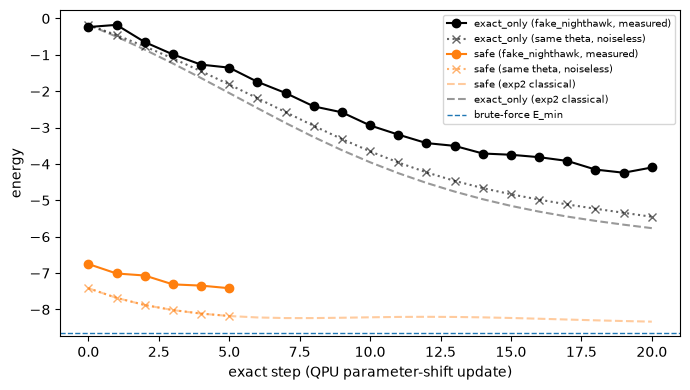

In [11]:
# arm별로 저장된 step 기록을 모아 회로 수, shots, AR 처음/끝을 정리
summary = {}
for arm in ["safe", "exact_only"]:
    rec = json.loads((OUT_ROOT / arm / "params.json").read_text())
    pts = rec["steps"] + [rec["final"]]                  # 업데이트 step들 + 최종 에너지
    n_circ = sum(p["n_circuits"] for p in pts)
    summary[arm] = {"updates": len(rec["steps"]), "circuits": n_circ, "shots": n_circ * SHOTS,
                    "ar_first": pts[0]["ar"], "ar_last": pts[-1]["ar"],
                    "ar_noiseless_first": pts[0]["ar_noiseless"], "ar_noiseless_last": pts[-1]["ar_noiseless"],
                    "energy": [p["energy"] for p in pts], "energy_noiseless": [p["energy_noiseless"] for p in pts]}
    s = summary[arm]
    print(f"{arm:10s} updates={s['updates']:2d}  circuits={s['circuits']:5d}  shots={s['shots']:8d}  "
          f"AR {s['ar_first']:.4f} -> {s['ar_last']:.4f}  (noiseless {s['ar_noiseless_first']:.4f} -> {s['ar_noiseless_last']:.4f})")
save_json(OUT_ROOT / "summary.json", {"backend": backend.name, "shots_per_circuit": SHOTS, "arms": summary})

# 고전 기준선 (실험 2, 같은 인스턴스와 같은 c)
ref = REPO / "results_on_MI300X" / "exp2_classical_3x3" / CASE
ref_safe = [r for r in json.loads((ref / "safe" / "params.json").read_text())["inits"] if r["c"] == start["config"]["const"]][0]
ref_long = [r for r in json.loads((ref / "exact_only_long" / "params.json").read_text())["inits"] if r["c"] == start["config"]["const"]][0]

fig, ax = plt.subplots(figsize=(7, 4))
for arm, color in [("exact_only", "black"), ("safe", "tab:orange")]:
    ax.plot(summary[arm]["energy"], "o-", color=color, label=f"{arm} ({backend.name}, measured)")
    ax.plot(summary[arm]["energy_noiseless"], "x:", color=color, alpha=0.6, label=f"{arm} (same theta, noiseless)")
ax.plot(ref_safe["energy"], "--", color="tab:orange", alpha=0.4, label="safe (exp2 classical)")
ax.plot(ref_long["energy"][:len(ref_safe["energy"])], "--", color="black", alpha=0.4, label="exact_only (exp2 classical)")
ax.axhline(e_min, color="tab:blue", linestyle="--", linewidth=1, label="brute-force E_min")
ax.set_xlabel("exact step (QPU parameter-shift update)")
ax.set_ylabel("energy")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT_ROOT / "summary.png", dpi=150)
print(f"classical reference (exp2, c={start['config']['const']}): exact-only needed {ref_long['steps_to_target']} steps "
      f"to reach the classical SAFE final AR {ref_long['target_ar']:.4f}")